# identify the order of sleep sessions

In [1]:
from collections import namedtuple
import loren_frank_data_processing.neurons as lf_neurons 
from scipy.io import loadmat
import pandas as pd
from glob import glob
import numpy as np
from pathlib import Path
import sys
sys.path.append("/home/dekorvyb/Documents/criticality_pipeline/")
import loren_frank_data.loren_frank_helper_functions as lf_helper


# Creating dictionary with animal file paths
# Defining each animal via its short name and its directory
Animal = namedtuple('Animal', {'short_name', 'directory'})

In [26]:
def load_task_file(file_name, animal):
    '''
    This function is mostly taken from loren frank lab.
    '''
    
    data = loadmat(file_name, variable_names=('task'))['task']
    #print(data.dtype.names)
    
    # data.shape returns a tuple (a,b), b being the number of days in the array
    n_days = data.shape[-1]
    
    epochs = data[0, -1][0]
    n_epochs = len(epochs)
    
    index = pd.MultiIndex.from_product(
        ([animal.short_name], [n_days], np.arange(n_epochs) + 1),
        names=['animal', 'day', 'epoch'])
    

    # Create a DataFrame from a list of dictionaries
    df_list = [
        {name: epoch[name].item().squeeze() 
         for name in epoch.dtype.names if name =='type'}
        for epoch in epochs]
    
    
    df = pd.DataFrame(df_list)

    # Set index and convert data types
    df = df.set_index(index).assign(
        type=lambda df: df.type.astype(str)
    )

    return df

In [3]:
# 1. Setup path and list all parquet files
data_dir = Path("/groups/cns/share/Vincent/loren_frank/mr_analysis_with_new_pipeline/")
file_list = list(data_dir.glob("*.parquet"))

# 2. Parse filenames into a helper DataFrame
file_data = []
for f in file_list:
    parts = f.stem.split('_')
    # Pattern: name_area_session_day_session-number_timechunk
    if parts[2] == 'sleep':
        file_data.append({
            'file_path': f,
            'name': parts[0],
            'area': parts[1],
            'day': parts[3],
            'session_num': int(parts[4]),
            'timechunk': parts[5]
        })

df_files = pd.DataFrame(file_data)

# 3. Identify "pre" (1st sleep) and "post" (2nd sleep) per name-area-day
def label_pre_post(group):
    # Get unique session numbers sorted ascending
    unique_sessions = sorted(group['session_num'].unique())
    
    # Map the first session to 'pre' and second to 'post'
    session_map = {}
    if len(unique_sessions) >= 1:
        session_map[unique_sessions[0]] = 'pre'
    if len(unique_sessions) >= 2:
        session_map[unique_sessions[1]] = 'post'
    
    group['session_label'] = group['session_num'].map(session_map)
    return group

# Apply the labeling; discard any sessions beyond the first two
df_files = df_files.groupby(['name', 'area', 'day'], group_keys=False).apply(label_pre_post)
df_files = df_files.dropna(subset=['session_label'])

# 4. Load the data from the selected files
final_rows = []
for _, row in df_files.iterrows():
    # Load the single-row parquet
    temp_df = pd.read_parquet(row['file_path'])
    
    # Extract required columns and add metadata
    final_rows.append({
        'name': row['name'],
        'area': row['area'],
        'day': row['day'],
        'session': row['session_label'],
        'tau': temp_df['tau'].iloc[0],
        'num_neurons': temp_df['num_neurons'].iloc[0],
        'timechunk': row['timechunk'] # keeping this to distinguish rows
    })

result_df = pd.DataFrame(final_rows)

print(result_df.head())

/tmp/ipykernel_3284491/3189395130.py:38: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_files = df_files.groupby(['name', 'area', 'day'], group_keys=False).apply(label_pre_post)


  name area day session          tau  num_neurons timechunk
0  con  CA1  06    post     9.471590           11        04
1  con  CA1  05     pre   666.849564           15        06
2  ten  CA3  02     pre  1533.460787           35        09
3  egy  ctx  07     pre   295.743914            2        09
4  con  CA3  04    post  1708.901060           19        08


/tmp/ipykernel_3245487/1752688775.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


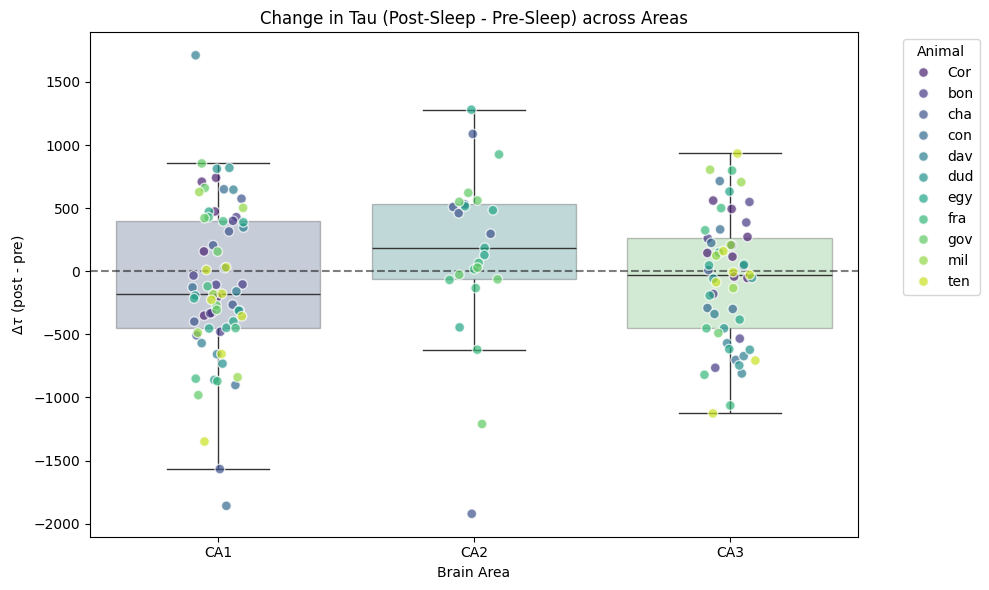

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Aggregate to get one 'pre' and 'post' value per Animal-Day-Area
df_diff = result_df.groupby(['name', 'day', 'area', 'session'])['tau'].mean().reset_index()

# 2. Pivot 'session' to columns
df_pivot = df_diff.pivot_table(
    index=['name', 'day', 'area'], 
    columns='session', 
    values='tau'
).reset_index()

# 3. Calculate the difference (Post - Pre)
# A positive value means Tau increased after the intervening activity
df_pivot['tau_diff'] = df_pivot['post'] - df_pivot['pre']

# 4. Filter for the specific hippocampal areas and sort them
target_areas = ["CA1", "CA2", "CA3"]
df_plot = df_pivot[df_pivot['area'].isin(target_areas)].copy()
df_plot['area'] = pd.Categorical(df_plot['area'], categories=target_areas, ordered=True)

# 5. Create the Plot
plt.figure(figsize=(10, 6))

# Boxplot for the distribution summary
sns.boxplot(
    data=df_plot, x='area', y='tau_diff', 
    palette='viridis', boxprops=dict(alpha=.3), showfliers=False
)

# Stripplot to show every individual Animal-Day point
sns.stripplot(
    data=df_plot, x='area', y='tau_diff', 
    hue='name', palette='viridis', alpha=0.7, linewidth=1, edgecolor='white', size=7
)

# 6. Formatting
plt.axhline(0, color='black', lw=1.5, ls='--', alpha=0.5) # Zero line = No change
plt.title('Change in Tau (Post-Sleep - Pre-Sleep) across Areas')
plt.ylabel(r'$\Delta \tau$ (post - pre)')
plt.xlabel('Brain Area')

# Move legend outside
plt.legend(title='Animal', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

/tmp/ipykernel_3284491/3769982493.py:27: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
/tmp/ipykernel_3284491/3769982493.py:27: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2.5}` instead.

  sns.pointplot(


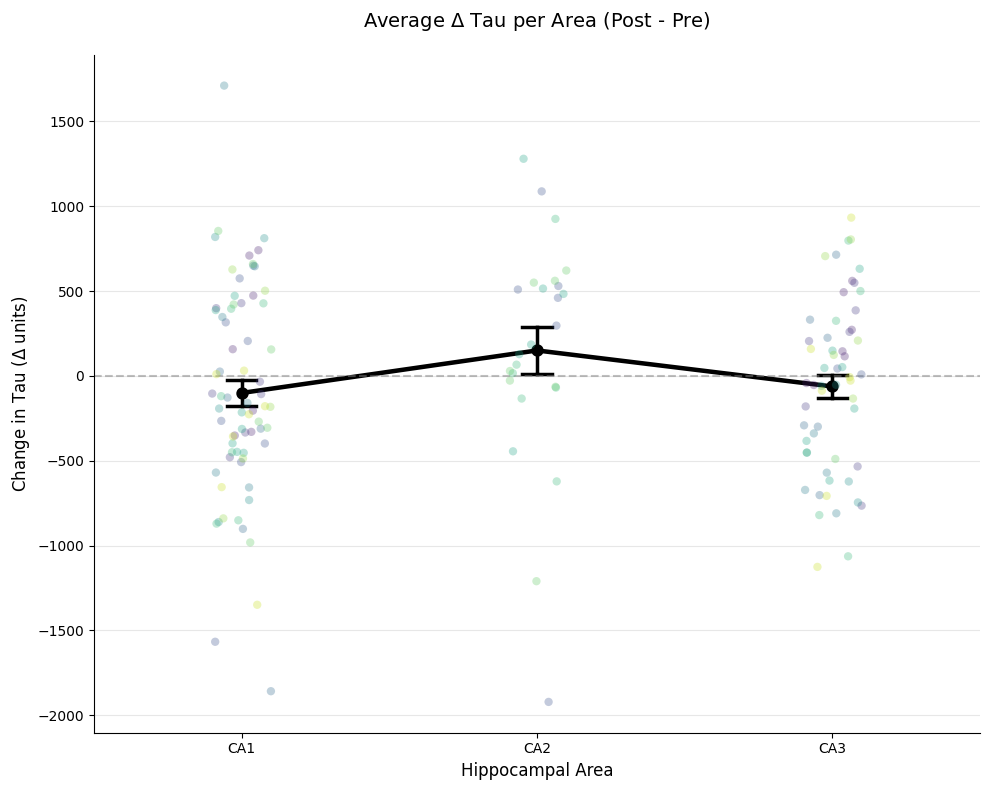

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Aggregate to one pre and post value per Animal-Day-Area
df_agg = result_df.groupby(['name', 'day', 'area', 'session'])['tau'].mean().reset_index()

# 2. Pivot to calculate the difference
df_pivot = df_agg.pivot_table(
    index=['name', 'day', 'area'], 
    columns='session', 
    values='tau'
).reset_index()

df_pivot['tau_diff'] = df_pivot['post'] - df_pivot['pre']

# 3. Filter and set order for CA1, CA2, CA3
target_areas = ["CA1", "CA2", "CA3"]
df_plot = df_pivot[df_pivot['area'].isin(target_areas)].copy()
df_plot['area'] = pd.Categorical(df_plot['area'], categories=target_areas, ordered=True)

# 4. Create the Point Plot (Mean connected by lines + SE Bars)
plt.figure(figsize=(10, 8)) # Wide format
ax = plt.gca()

# Show the mean and Standard Error (SE) as vertical bars
sns.pointplot(
    data=df_plot, 
    x='area', 
    y='tau_diff', 
    errorbar='se',      # Use Standard Error
    capsize=0.1,        # Horizontal caps on the error bars
    color='black',      # Trajectory color
    markers='o',        # Mean markers
    scale=1.2,          # Size of markers/lines
    errwidth=2.5,       # Thickness of error bars
    ax=ax
)

# Optional: Overlay individual animal-day points for transparency
sns.stripplot(
    data=df_plot, x='area', y='tau_diff', hue='name', 
    palette='viridis', alpha=0.3, size=6, dodge=False, legend=False
)

# Reference line for zero change
plt.axhline(0, color='gray', lw=1.5, ls='--', alpha=0.5)

# Formatting
plt.title(r'Average $\Delta$ Tau per Area (Post - Pre)', fontsize=14, pad=20)
plt.ylabel(r'Change in Tau ($\Delta$ units)', fontsize=12)
plt.xlabel('Hippocampal Area', fontsize=12)

# Styling for a clean, professional look
sns.despine()
plt.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Statistics

In [ ]:
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 1. Perform the One-Way ANOVA
# Assuming 'df' has columns 'subregion' and 'tau_level'
df_clean = df_pivot.dropna(subset=['tau_diff'])
df_clean = df_clean[~df_clean['area'].isin(['DG'])]


groups = [group['tau_diff'].values for name, group in df_clean.groupby('area')]
f_stat, p_val = stats.f_oneway(*groups)

print(f"ANOVA Result: F={f_stat:.2f}, p-value={p_val:.4f}")

# 2. If p < 0.05, perform Post-hoc Tukey HSD
if p_val < 0.05:
    print("Significant difference found. Running Tukey HSD...")
    tukey = pairwise_tukeyhsd(endog=df_clean['tau_diff'], 
                              groups=df_clean['area'], 
                              alpha=0.05)
    print(tukey)
else:
    print("No significant difference detected.")

TypeError: bad operand type for unary ~: 'str'